# Proyecto final — Modelos y Simulación II

**Universidad de Antioquia · Facultad de Ingeniería**

- **Equipo:** Samuel Puerta Patiño, Simón Berrio Gaviria, Juan Estiven Carmona Muñoz
- **Grupo:** 5
- **Semestre:** 2026-2
- **Dataset:** *Financial Transactions & Fraud Detection* (Kaggle)

## Detección de fraude en transacciones financieras

**Entrega 1 — Sección 2: Descripción del problema**

| Apartado | Contenido |
|---|---|
| 1 | Configuración del entorno |
| 2.1 | Contexto del problema |
| 2.2 | Fuente y composición de la base de datos |
| 2.3 | Variable objetivo y desbalance |
| 2.4 | Variables numéricas |
| 2.5 | Variables categóricas |
| 2.6 | Variables temporales |
| 2.7 | Estructura por usuario |
| 2.8 | Relación entre variables explicativas |
| 2.9 | Fase de caracterización |
| 2.10 | Preprocesamiento y codificación |
| 2.11 | Paradigma de aprendizaje |
| — | Referencias |

## 1. Configuración

Librerías, semilla de reproducibilidad y rutas del proyecto. Las figuras se guardan en `report/figures/` en PDF (para el informe en LaTeX) y en PNG (para vista previa).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.proportion import proportion_confint

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path("../data/synthetic_financial_transactions.csv")
FIG_DIR = Path("../report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

COLOR_NORMAL = "#4C72B0"
COLOR_FRAUDE = "#C44E52"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 2. Descripción del problema

### 2.1 Contexto del problema

El fraude en transacciones financieras consiste en el uso no autorizado de medios de pago o de cuentas para obtener un beneficio ilegítimo. Es un problema que crece cada año con la expansión de los pagos electrónicos y que genera pérdidas importantes a entidades financieras y clientes [1], [2]. Los sistemas basados en reglas definidas manualmente no escalan al volumen actual de transacciones ni capturan patrones que no son evidentes para un analista, por lo que el aprendizaje de máquina se ha convertido en la alternativa más estudiada para esta tarea [1].

Detectar fraude es difícil por dos razones: la fuerte desproporción entre transacciones legítimas y fraudulentas [2], [3] y el solapamiento entre ambas clases en el espacio de características [2]. Además, los errores no cuestan lo mismo: un fraude no detectado (falso negativo) implica una pérdida directa, mientras que una falsa alarma (falso positivo) solo genera una revisión innecesaria o una molestia para el cliente. Por eso la evaluación no puede basarse en la exactitud global.

Un modelo de clasificación entrenado con transacciones etiquetadas permitiría asignar a cada transacción nueva una probabilidad de fraude y, con base en ella, decidir si se aprueba, se bloquea o se envía a revisión manual. El conjunto de datos de este proyecto es sintético, de modo que los resultados describen el comportamiento de los modelos sobre estos datos y no son extrapolables directamente a un sistema real.

### 2.2 Fuente y composición de la base de datos

Se usa el conjunto *Financial Transactions & Fraud Detection*, publicado en Kaggle [5]. Según su descripción, contiene 10.000 transacciones personales **sintéticas** registradas durante un año (agosto de 2025 a agosto de 2026), generadas con distribuciones realistas (montos log-normales y preferencias de gasto por usuario) y pensadas para detección de fraude y análisis de riesgo. La variable `is_fraud` es la etiqueta de referencia. La variable `risk_score` se describe como un puntaje de riesgo continuo ya calculado (*engineered*), sin que se documente cómo se obtuvo.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
print(f"Muestras: {df.shape[0]:,} | Variables: {df.shape[1]}")
df.head()

Muestras: 10,000 | Variables: 11


,transaction_id,timestamp,user_id,account_type,category,amount,currency,payment_method,device_type,risk_score,is_fraud
0,TXN_100000,2025-08-26 08:02:13.821309,USR_5559,Checking,Electronics,22.920,USD,Debit Card,Desktop,36.510,0
1,TXN_100001,2025-08-26 08:24:13.821309,USR_6322,Checking,Dining,17.890,USD,Debit Card,POS Terminal,16.890,0
2,TXN_100002,2025-08-26 09:53:13.821309,USR_2845,Checking,Online Transfer,12.420,USD,Debit Card,ATM,6.680,0
3,TXN_100003,2025-08-26 10:26:13.821309,USR_9984,Savings,Groceries,28.700,USD,Credit Card,ATM,73.640,1
4,TXN_100004,2025-08-26 11:16:13.821309,USR_5988,Savings,Travel,9.270,USD,Debit Card,Desktop,42.340,0


**Diccionario de variables.** Rol, significado, tipo, número de valores distintos, datos faltantes y un valor de ejemplo de cada variable.

In [3]:
roles = {
    "transaction_id": "Identificador",
    "timestamp": "Temporal",
    "user_id": "Identificador",
    "account_type": "Categórica",
    "category": "Categórica",
    "amount": "Numérica",
    "currency": "Constante",
    "payment_method": "Categórica",
    "device_type": "Categórica",
    "risk_score": "Numérica",
    "is_fraud": "Objetivo",
}

descripciones = {
    "transaction_id": "Identificador único de la transacción",
    "timestamp": "Fecha y hora de la transacción",
    "user_id": "Identificador único del cliente",
    "account_type": "Tipo de cuenta usada (Checking, Savings, Credit Card)",
    "category": "Categoría del gasto (Groceries, Electronics, Travel, etc.)",
    "amount": "Valor de la transacción en dólares (USD)",
    "currency": "Código ISO de la moneda",
    "payment_method": "Canal de pago (Debit Card, Credit Card, UPI, Bank Transfer)",
    "device_type": "Dispositivo o terminal (Desktop, Mobile, POS Terminal, ATM)",
    "risk_score": "Puntaje de riesgo precalculado, en el rango 0–100",
    "is_fraud": "Etiqueta: 0 = transacción normal, 1 = fraude",
}

diccionario = pd.DataFrame({
    "rol": pd.Series(roles),
    "descripción": pd.Series(descripciones),
    "tipo": df.dtypes.astype(str),
    "valores_distintos": df.nunique(),
    "faltantes": df.isna().sum(),
    "ejemplo": df.iloc[0].astype(str),
})
diccionario

,rol,descripción,tipo,valores_distintos,faltantes,ejemplo
transaction_id,Identificador,Identificador único de la transacción,object,10000,0,TXN_100000
timestamp,Temporal,Fecha y hora de la transacción,datetime64[ns],9921,0,2025-08-26 08:02:13.821309
user_id,Identificador,Identificador único del cliente,object,2142,0,USR_5559
account_type,Categórica,"Tipo de cuenta usada (Checking, Savings, Credi...",object,3,0,Checking
category,Categórica,"Categoría del gasto (Groceries, Electronics, T...",object,8,0,Electronics
amount,Numérica,Valor de la transacción en dólares (USD),float64,6104,0,22.92
currency,Constante,Código ISO de la moneda,object,1,0,USD
payment_method,Categórica,"Canal de pago (Debit Card, Credit Card, UPI, B...",object,4,0,Debit Card
device_type,Categórica,"Dispositivo o terminal (Desktop, Mobile, POS T...",object,4,0,Desktop
risk_score,Numérica,"Puntaje de riesgo precalculado, en el rango 0–100",float64,4811,0,36.51


**Calidad de los datos.** Se verifican duplicados, identificadores repetidos, valores faltantes, la constancia de `currency` y el rango temporal.

In [4]:
calidad = pd.Series({
    "Filas duplicadas": df.duplicated().sum(),
    "transaction_id repetidos": df["transaction_id"].duplicated().sum(),
    "Valores faltantes": df.isna().sum().sum(),
    "Valores distintos de currency": df["currency"].nunique(),
    "Usuarios distintos": df["user_id"].nunique(),
    "Primera transacción": df["timestamp"].min(),
    "Última transacción": df["timestamp"].max(),
}).astype(str).to_frame("valor")
calidad

,valor
Filas duplicadas,0
transaction_id repetidos,0
Valores faltantes,0
Valores distintos de currency,1
Usuarios distintos,2142
Primera transacción,2025-08-26 08:02:13.821309
Última transacción,2026-08-26 04:30:13.821309


El conjunto contiene **10.000 transacciones de 2.142 usuarios**, registradas entre el 26 de agosto de 2025 y el 26 de agosto de 2026, y descritas por **11 variables**: dos identificadores (`transaction_id`, `user_id`), una marca de tiempo (`timestamp`), cuatro variables categóricas (`account_type`, `category`, `payment_method`, `device_type`), dos numéricas (`amount`, `risk_score`), la moneda (`currency`) y la etiqueta `is_fraud`.

No hay valores faltantes, filas duplicadas ni identificadores de transacción repetidos, por lo que **no se requiere imputación**. La variable `currency` es constante (USD) y no aporta información, por lo que se descarta.

### 2.3 Variable objetivo y desbalance

In [5]:
conteo = df["is_fraud"].value_counts().rename({0: "Normal", 1: "Fraude"})
tabla_clase = pd.DataFrame({"n": conteo, "porcentaje": 100 * conteo / len(df)})
tabla_clase

,n,porcentaje
is_fraud,,
Normal,9874,98.740
Fraude,126,1.260


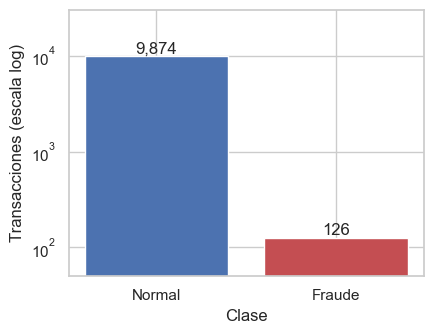

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(tabla_clase.index, tabla_clase["n"], color=[COLOR_NORMAL, COLOR_FRAUDE])
ax.set_yscale("log")
ax.set_ylim(50, 3e4)
ax.set_xlabel("Clase")
ax.set_ylabel("Transacciones (escala log)")
for i, v in enumerate(tabla_clase["n"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
savefig("fig_desbalance")
plt.show()

*Figura 1. Número de transacciones por clase (eje vertical en escala logarítmica).*

La clase positiva está fuertemente desbalanceada: **126 fraudes (1,26 %)** frente a 9.874 transacciones normales (98,74 %). Un clasificador que nunca predijera fraude alcanzaría una exactitud cercana al 98,7 %, por lo que la exactitud no sirve como criterio de evaluación en este problema.

### 2.4 Variables numéricas

Estadísticos descriptivos de `amount` y `risk_score` por clase (0 = normal, 1 = fraude) y asimetría de `amount` antes y después de la transformación logarítmica.

In [7]:
df.groupby("is_fraud")[["amount", "risk_score"]].describe().T

is_fraud                 0       1
amount     count 9,874.000 126.000
           mean     49.583  53.882
           std      72.195  83.435
           min       1.500   1.500
           25%      12.910  11.672
           50%      27.370  25.395
           75%      57.710  54.445
           max   1,668.900 508.460
risk_score count 9,874.000 126.000
           mean     28.534  38.559
           std      15.632  24.362
           min       0.310   2.640
           25%      16.233  18.642
           50%      26.565  33.275
           75%      39.108  59.208
           max      88.350  89.240

In [8]:
df["amount_log"] = np.log1p(df["amount"])
pd.Series({
    "amount": df["amount"].skew(),
    "log(1 + amount)": df["amount_log"].skew(),
    "risk_score": df["risk_score"].skew(),
}).to_frame("asimetría")

,asimetría
amount,5.682
log(1 + amount),0.139
risk_score,0.571


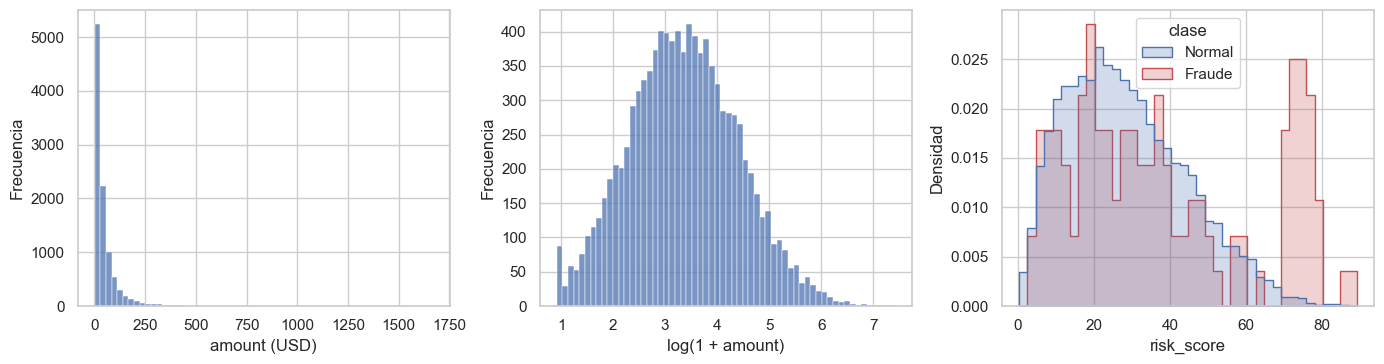

In [9]:
clase = df["is_fraud"].map({0: "Normal", 1: "Fraude"})

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(df["amount"], bins=60, color=COLOR_NORMAL, ax=axes[0])
axes[0].set_xlabel("amount (USD)")
axes[0].set_ylabel("Frecuencia")
sns.histplot(df["amount_log"], bins=60, color=COLOR_NORMAL, ax=axes[1])
axes[1].set_xlabel("log(1 + amount)")
axes[1].set_ylabel("Frecuencia")
sns.histplot(
    data=df.assign(clase=clase), x="risk_score", hue="clase",
    hue_order=["Normal", "Fraude"], palette=[COLOR_NORMAL, COLOR_FRAUDE],
    bins=40, stat="density", common_norm=False, element="step", ax=axes[2],
)
axes[2].set_xlabel("risk_score")
axes[2].set_ylabel("Densidad")
savefig("fig_numericas")
plt.show()

*Figura 2. Izquierda: distribución de `amount`. Centro: distribución de `log(1 + amount)`. Derecha: densidad de `risk_score` por clase.*

**Diferencias entre clases.** Se usa la prueba de Mann-Whitney U (no paramétrica, adecuada para distribuciones asimétricas) y el área bajo la curva ROC univariada como índice de discriminación: 0,5 indica que la variable no separa las clases y 1,0 que las separa perfectamente.

In [10]:
filas = []
for col in ["amount", "risk_score"]:
    fraude = df.loc[df["is_fraud"] == 1, col]
    normal = df.loc[df["is_fraud"] == 0, col]
    _, p = stats.mannwhitneyu(fraude, normal, alternative="two-sided")
    filas.append({
        "variable": col,
        "mediana_fraude": fraude.median(),
        "mediana_normal": normal.median(),
        "p_mann_whitney": f"{p:.2e}",
        "auc_univariada": roc_auc_score(df["is_fraud"], df[col]),
    })
pd.DataFrame(filas).set_index("variable")

,mediana_fraude,mediana_normal,p_mann_whitney,auc_univariada
variable,,,,
amount,25.395,27.370,7.02e-01,0.490
risk_score,33.275,26.565,8.32e-05,0.602


**Grupo de fraudes con `risk_score` alto.** La Figura 2 sugiere que los fraudes no siguen una sola distribución en `risk_score`. Para cuantificarlo se calcula, para varios umbrales, qué porcentaje de fraudes y de transacciones normales queda por encima y cuál sería la precisión de una regla simple que marcara como fraude todo lo que supere el umbral.

In [11]:
filas = []
for umbral in (60, 65, 70):
    alerta = df["risk_score"] >= umbral
    filas.append({
        "umbral": umbral,
        "fraudes_sobre_umbral_%": 100 * alerta[df["is_fraud"] == 1].mean(),
        "normales_sobre_umbral_%": 100 * alerta[df["is_fraud"] == 0].mean(),
        "transacciones_alertadas": alerta.sum(),
        "precision_regla_%": 100 * df.loc[alerta, "is_fraud"].mean(),
    })
pd.DataFrame(filas).set_index("umbral")

,fraudes_sobre_umbral_%,normales_sobre_umbral_%,transacciones_alertadas,precision_regla_%
umbral,,,,
60,24.603,3.605,387,8.010
65,23.810,1.681,196,15.306
70,23.810,0.668,96,31.250


**¿Quiénes son los fraudes con `risk_score` alto?** Se compara el grupo de fraudes con `risk_score` ≥ 65 contra el resto de fraudes en las demás variables. Con tan pocos casos por nivel, los p-valores de χ² son solo orientativos.

In [12]:
fraudes = df[df["is_fraud"] == 1].copy()
fraudes["grupo"] = np.where(fraudes["risk_score"] >= 65, "risk_score alto", "resto")
alto = fraudes["grupo"] == "risk_score alto"
print(f"Fraudes con risk_score >= 65: {alto.sum()} (mínimo {fraudes.loc[alto, 'risk_score'].min():.2f})")

filas = []
for col in ["account_type", "category", "payment_method", "device_type"]:
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(fraudes[col], fraudes["grupo"]))
    filas.append({"variable": col, "prueba": "χ²", "p_valor": p})
_, p = stats.mannwhitneyu(fraudes.loc[alto, "amount"], fraudes.loc[~alto, "amount"])
filas.append({"variable": "amount", "prueba": "Mann-Whitney U", "p_valor": p})
pd.DataFrame(filas).set_index("variable")

Fraudes con risk_score >= 65: 30 (mínimo 70.02)


,prueba,p_valor
variable,,
account_type,χ²,0.928
category,χ²,0.871
payment_method,χ²,0.957
device_type,χ²,0.849
amount,Mann-Whitney U,0.578


**`amount`.** El monto está muy sesgado a la derecha (asimetría 5,68; mediana 27,36 USD; máximo 1.668,90 USD). Con la transformación `log(1 + amount)` la asimetría baja a 0,14, por lo que se usará esta versión. El monto no distingue las clases: las medianas son 25,4 USD en fraudes y 27,4 USD en normales (Mann-Whitney, p = 0,70; AUC univariada 0,49).

**`risk_score`.** Es la única variable con diferencias significativas entre clases (medianas 33,3 en fraudes y 26,6 en normales; p = 8,3·10⁻⁵), pero su AUC univariada es solo 0,60. La razón es que los fraudes forman dos grupos: cerca del 24 % tiene `risk_score` ≥ 65, frente a solo el 1,7 % de las transacciones normales, y el resto se parece a las transacciones normales. Una regla simple con umbral 70 captura el 23,8 % de los fraudes con una precisión del 31,2 %. Esta es la señal más fuerte del conjunto de datos, pero cubre menos de una cuarta parte de los fraudes.

**Posible fuga de información.** `risk_score` es un puntaje ya calculado cuyo origen no se documenta en la fuente. Además, los 30 fraudes del grupo alto (todos con `risk_score` ≥ 70) no se diferencian del resto de fraudes en ninguna otra variable (χ², p ≥ 0,85; monto, p = 0,58): el puntaje alto aparece en un subconjunto de fraudes sin relación con las demás características. Esto es compatible con que el generador sintético haya construido `risk_score` usando la etiqueta, lo que inflaría de forma artificial el desempeño de los modelos. Por eso, en la sección 4 los modelos se entrenarán y evaluarán **con y sin** esta variable.

### 2.5 Variables categóricas

Para cada nivel de las cuatro variables categóricas se calcula la tasa de fraude con su intervalo de confianza de Wilson al 95 %, que es más fiable que el intervalo normal cuando la proporción es pequeña. La asociación con el fraude se evalúa con la prueba χ² de independencia, verificando que el número mínimo de fraudes esperados por nivel sea al menos 5.

In [13]:
CATEGORICAS = ["account_type", "category", "payment_method", "device_type"]
TASA_GLOBAL = 100 * df["is_fraud"].mean()


def tabla_fraude(col):
    tabla = df.groupby(col)["is_fraud"].agg(n="count", fraudes="sum")
    tabla["tasa_%"] = 100 * tabla["fraudes"] / tabla["n"]
    inferior, superior = proportion_confint(tabla["fraudes"], tabla["n"], method="wilson")
    tabla["ic95_inf_%"] = 100 * inferior
    tabla["ic95_sup_%"] = 100 * superior
    return tabla.sort_values("tasa_%", ascending=False)


pd.concat({col: tabla_fraude(col) for col in CATEGORICAS}, names=["variable", "nivel"])

n  fraudes  tasa_%  ic95_inf_%  ic95_sup_%
variable       nivel                                                         
account_type   Savings          3992       56   1.403       1.082       1.817
               Credit Card      1453       20   1.376       0.893       2.117
               Checking         4555       50   1.098       0.834       1.444
category       Travel            822       13   1.582       0.927       2.687
               Online Transfer  1029       16   1.555       0.959       2.511
               Electronics      1018       15   1.473       0.895       2.417
               Groceries        2515       34   1.352       0.969       1.883
               Utilities        1220       15   1.230       0.746       2.019
               Entertainment     962       10   1.040       0.566       1.903
               Dining           1944       19   0.977       0.627       1.522
               Healthcare        490        4   0.816       0.318       2.080
payment_method Debit Card       3451       47   1.362       1.026       1.806
               Credit Card      3602       47   1.305       0.983       1.731
               Bank Transfer     977       11   1.126       0.630       2.005
               UPI              1970       21   1.066       0.698       1.624
device_type    Mobile           5472       73   1.334       1.062       1.674
               POS Terminal     1034       13   1.257       0.736       2.139
               ATM               965       12   1.244       0.713       2.161
               Desktop          2529       28   1.107       0.767       1.596

In [14]:
filas = []
for col in CATEGORICAS:
    contingencia = pd.crosstab(df[col], df["is_fraud"])
    chi2, p, gl, esperados = stats.chi2_contingency(contingencia)
    filas.append({
        "variable": col,
        "niveles": df[col].nunique(),
        "chi2": chi2,
        "gl": gl,
        "p_valor": p,
        "min_fraudes_esperados": esperados[:, 1].min(),
    })
pd.DataFrame(filas).set_index("variable")

,niveles,chi2,gl,p_valor,min_fraudes_esperados
variable,,,,,
account_type,3,1.777,2,0.411,18.308
category,8,4.354,7,0.738,6.174
payment_method,4,1.084,3,0.781,12.310
device_type,4,0.718,3,0.869,12.159


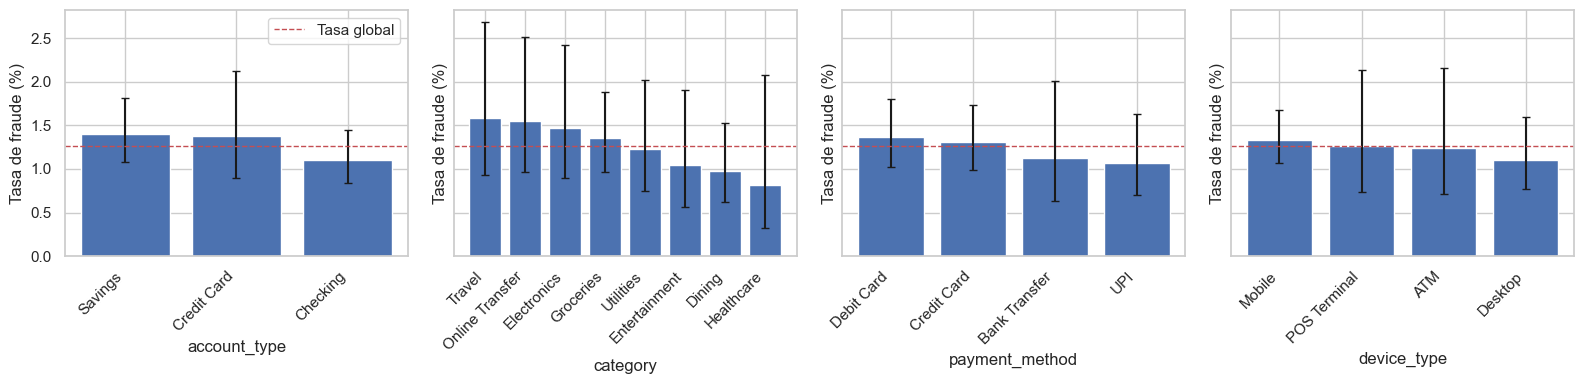

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, CATEGORICAS):
    tabla = tabla_fraude(col).reset_index()
    error = [tabla["tasa_%"] - tabla["ic95_inf_%"], tabla["ic95_sup_%"] - tabla["tasa_%"]]
    ax.bar(tabla[col], tabla["tasa_%"], yerr=error, capsize=3, color=COLOR_NORMAL)
    ax.axhline(TASA_GLOBAL, color=COLOR_FRAUDE, ls="--", lw=1, label="Tasa global")
    ax.set_xlabel(col)
    ax.set_ylabel("Tasa de fraude (%)")
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
axes[0].legend(loc="upper right")
savefig("fig_tasa_fraude_categoricas")
plt.show()

*Figura 3. Tasa de fraude por nivel de cada variable categórica, con intervalos de confianza de Wilson al 95 %. La línea discontinua marca la tasa global (1,26 %).*

Ninguna variable categórica muestra asociación significativa con el fraude (χ²: `account_type` p = 0,41; `category` p = 0,74; `payment_method` p = 0,78; `device_type` p = 0,87). Los intervalos de Wilson de todos los niveles contienen la tasa global, y en las cuatro variables el mínimo de fraudes esperados por nivel supera 5, por lo que se cumple el supuesto de la prueba. Las diferencias que se ven en la Figura 3 son compatibles con variación aleatoria.

### 2.6 Variables temporales

A partir de `timestamp` se derivan la hora, el día de la semana, el mes y una franja horaria de seis horas. Como algunos niveles de hora y mes tienen menos de 5 fraudes esperados, la prueba χ² clásica no es apropiada. En su lugar se usa una **prueba de permutación** sobre el estadístico χ²: la etiqueta se permuta 5.000 veces y el p-valor es la fracción de permutaciones con un estadístico mayor o igual al observado.

In [16]:
df["hour"] = df["timestamp"].dt.hour
df["dayofweek"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.to_period("M").astype(str)
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
df["franja"] = pd.cut(
    df["hour"], [-1, 5, 11, 17, 23], labels=["00-05", "06-11", "12-17", "18-23"]
).astype(str)

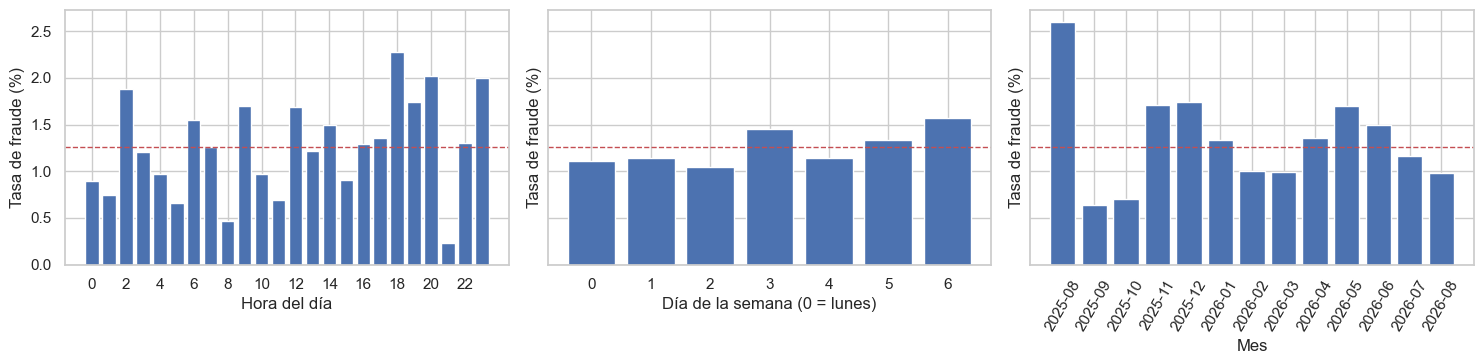

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
etiquetas = {"hour": "Hora del día", "dayofweek": "Día de la semana (0 = lunes)", "month": "Mes"}
for ax, (col, etiqueta) in zip(axes, etiquetas.items()):
    tasa = df.groupby(col)["is_fraud"].mean() * 100
    ax.bar(tasa.index.astype(str), tasa.values, color=COLOR_NORMAL)
    ax.axhline(TASA_GLOBAL, color=COLOR_FRAUDE, ls="--", lw=1)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Tasa de fraude (%)")
axes[0].set_xticks(range(0, 24, 2))
axes[2].tick_params(axis="x", rotation=60)
savefig("fig_temporal")
plt.show()

*Figura 4. Tasa de fraude por hora del día, día de la semana y mes. La línea discontinua marca la tasa global (1,26 %).*

In [18]:
def chi2_estadistico(codigos, y, k):
    fraudes = np.bincount(codigos, weights=y, minlength=k)
    totales = np.bincount(codigos, minlength=k)
    esperados_fraude = totales * y.mean()
    esperados_normal = totales * (1 - y.mean())
    return (
        (fraudes - esperados_fraude) ** 2 / esperados_fraude
        + ((totales - fraudes) - esperados_normal) ** 2 / esperados_normal
    ).sum()


def prueba_permutacion(col, permutaciones=5000, semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    codigos, niveles = pd.factorize(df[col])
    y = df["is_fraud"].to_numpy(dtype=float)
    observado = chi2_estadistico(codigos, y, len(niveles))
    simulados = np.array([
        chi2_estadistico(codigos, rng.permutation(y), len(niveles))
        for _ in range(permutaciones)
    ])
    return observado, (1 + (simulados >= observado).sum()) / (permutaciones + 1)


filas = []
for col in ["hour", "dayofweek", "month", "franja"]:
    observado, p = prueba_permutacion(col)
    filas.append({
        "variable": col,
        "niveles": df[col].nunique(),
        "min_fraudes_esperados": (df.groupby(col).size() * df["is_fraud"].mean()).min(),
        "chi2_observado": observado,
        "p_permutacion": p,
    })
pd.DataFrame(filas).set_index("variable")

,niveles,min_fraudes_esperados,chi2_observado,p_permutacion
variable,,,,
hour,24,4.423,21.035,0.580
dayofweek,7,17.098,2.707,0.837
month,13,1.940,12.842,0.377
franja,4,31.046,3.395,0.336


In [19]:
df.groupby("month")["is_fraud"].agg(transacciones="size", fraudes="sum").T

month,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
transacciones,154,777,848,817,862,826,801,908,811,822,803,856,715
fraudes,4,5,6,14,15,11,8,9,11,14,12,10,7


La tasa de fraude no varía de forma apreciable con el momento de la transacción. Los p-valores de permutación fueron 0,58 para la hora, 0,84 para el día de la semana, 0,38 para el mes y 0,34 para la franja horaria; ninguno es significativo. Las barras con tasas altas o bajas en la Figura 4 se explican por el bajo número de fraudes por nivel. Por ejemplo, agosto de 2025 solo tiene 154 transacciones porque el registro empieza el día 26, de modo que su tasa del 2,6 % no es fiable. Agosto de 2026 también está incompleto, ya que el registro termina el día 26.

### 2.7 Estructura por usuario

Cada usuario aporta varias transacciones, así que se revisa cómo se reparten las transacciones y los fraudes entre usuarios.

In [20]:
por_usuario = df.groupby("user_id")["is_fraud"].agg(transacciones="size", fraudes="sum")
pd.Series({
    "Usuarios": len(por_usuario),
    "Transacciones por usuario (media)": round(por_usuario["transacciones"].mean(), 2),
    "Transacciones por usuario (mediana)": int(por_usuario["transacciones"].median()),
    "Transacciones por usuario (máximo)": por_usuario["transacciones"].max(),
    "Usuarios con al menos un fraude": (por_usuario["fraudes"] > 0).sum(),
    "Usuarios con más de un fraude": (por_usuario["fraudes"] > 1).sum(),
}, dtype=object).to_frame("valor")

,valor
Usuarios,2142
Transacciones por usuario (media),4.670
Transacciones por usuario (mediana),4
Transacciones por usuario (máximo),18
Usuarios con al menos un fraude,124
Usuarios con más de un fraude,2


Cada usuario tiene en promedio 4,7 transacciones (mediana 4, máximo 18). Los 126 fraudes se reparten entre 124 usuarios y solo 2 usuarios tienen más de uno, de modo que el fraude no se concentra en pocos clientes. Este resultado se tendrá en cuenta al definir la estrategia de validación en la sección 4. Las variables que resumen el historial de cada usuario se construyen en la fase de caracterización (sección 2.9).

### 2.8 Relación entre variables explicativas

Se verifica si `risk_score` depende del canal, el dispositivo, el tipo de cuenta o la categoría (prueba de Kruskal-Wallis entre niveles) y si se relaciona con el monto (correlación de Spearman).

In [21]:
filas = []
for col in CATEGORICAS:
    medias = df.groupby(col)["risk_score"].mean()
    grupos = [grupo["risk_score"] for _, grupo in df.groupby(col)]
    _, p = stats.kruskal(*grupos)
    filas.append({
        "variable": col,
        "risk_score_medio_min": medias.min(),
        "risk_score_medio_max": medias.max(),
        "p_kruskal_wallis": p,
    })
pd.DataFrame(filas).set_index("variable")

,risk_score_medio_min,risk_score_medio_max,p_kruskal_wallis
variable,,,
account_type,28.640,28.720,0.936
category,27.745,29.206,0.338
payment_method,28.102,28.916,0.631
device_type,28.329,28.823,0.954


In [22]:
rho, p = stats.spearmanr(df["amount"], df["risk_score"])
pd.Series({"rho_spearman": rho, "p_valor": p}).to_frame("amount vs risk_score")

,amount vs risk_score
rho_spearman,0.014
p_valor,0.173


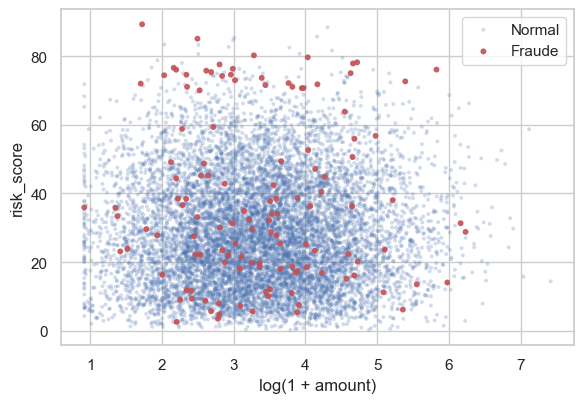

In [23]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for valor, nombre, color, alpha, tamano in [
    (0, "Normal", COLOR_NORMAL, 0.25, 8),
    (1, "Fraude", COLOR_FRAUDE, 0.9, 18),
]:
    sub = df[df["is_fraud"] == valor]
    ax.scatter(sub["amount_log"], sub["risk_score"], s=tamano, alpha=alpha,
               color=color, label=nombre, edgecolors="none")
ax.set_xlabel("log(1 + amount)")
ax.set_ylabel("risk_score")
ax.legend(loc="upper right")
savefig("fig_dispersion_risk_amount")
plt.show()

El promedio de `risk_score` es prácticamente igual en todos los niveles de las variables categóricas (entre 27,7 y 29,2; Kruskal-Wallis, p ≥ 0,34) y no hay correlación entre `amount` y `risk_score` (Spearman ρ = 0,014). Las variables explicativas son, en la práctica, independientes entre sí, de modo que no hay redundancia que obligue a descartar alguna en esta etapa.

*Figura 5. `risk_score` frente a `log(1 + amount)` por clase.*

La Figura 5 resume el problema: fuera de la franja con `risk_score` ≥ 70, los fraudes quedan completamente mezclados con las transacciones normales en todo el rango del monto. Las clases se solapan en el espacio de las variables originales, que es justamente una de las dificultades señaladas en la literatura [2].

### 2.9 Fase de caracterización

El conjunto de datos no llega como una matriz de características lista para entrenar, sino como un **registro de transacciones**: una marca de tiempo, el identificador del cliente y atributos categóricos en texto. Por eso, antes del modelado, se requiere una **fase de caracterización**, en la que se construye el vector de características de cada transacción a partir de los datos crudos. Las características se agrupan en tres familias:

1. **De la transacción:** `amount_log` (sección 2.4), `risk_score` y las cuatro variables categóricas codificadas (sección 2.10).
2. **Temporales**, derivadas de `timestamp`: hora del día en codificación cíclica (`hour_sin`, `hour_cos`) e indicador de fin de semana (`is_weekend`).
3. **De comportamiento del usuario**, que comparan cada transacción con el historial del cliente. En la literatura son de las variables más útiles para detectar fraude [4]. Se calculan usando **solo las transacciones anteriores** de cada usuario, para no filtrar información del futuro:

| Característica | Definición |
|---|---|
| `primera_transaccion` | 1 si es la primera transacción registrada del usuario |
| `transacciones_previas` | Número de transacciones anteriores del usuario |
| `horas_desde_anterior_log` | log(1 + horas desde la transacción anterior del usuario) |
| `desvio_log_monto` | `amount_log` menos el promedio de `amount_log` en las transacciones anteriores del usuario |
| `transacciones_24h`, `transacciones_7d` | Transacciones del usuario en las 24 horas / 7 días anteriores |
| `monto_7d_log` | log(1 + monto total gastado por el usuario en los 7 días anteriores) |
| `cambio_dispositivo`, `cambio_metodo_pago`, `cambio_categoria` | 1 si el dispositivo, el método de pago o la categoría cambian respecto a la transacción anterior |
| `dispositivo_nuevo` | 1 si el usuario nunca había usado ese tipo de dispositivo |

Las variables que dependen de una transacción previa no están definidas para la primera transacción de cada usuario; su imputación se describe en la sección 2.10.

In [24]:
ordenado = df.sort_values(["user_id", "timestamp"])
historial = ordenado.groupby("user_id")
tiene_previa = historial.cumcount() > 0
por_tiempo = ordenado.set_index("timestamp").groupby("user_id")


def en_ventana(ventana, agregacion):
    # Ventana previa de cada transacción (closed="left" excluye la transacción actual)
    movil = getattr(por_tiempo["amount"].rolling(ventana, closed="left"), agregacion)()
    assert (movil.index.get_level_values("user_id") == ordenado["user_id"].to_numpy()).all()
    return pd.Series(movil.to_numpy(), index=ordenado.index).fillna(0)


def cambio(col):
    return (historial[col].shift() != ordenado[col]).where(tiene_previa)


comportamiento = pd.DataFrame({
    "primera_transaccion": ~tiene_previa,
    "transacciones_previas": historial.cumcount(),
    "horas_desde_anterior_log": np.log1p(historial["timestamp"].diff().dt.total_seconds() / 3600),
    "desvio_log_monto": ordenado["amount_log"]
    - historial["amount_log"].transform(lambda s: s.shift().expanding().mean()),
    "transacciones_24h": en_ventana("24h", "count"),
    "transacciones_7d": en_ventana("7D", "count"),
    "monto_7d_log": np.log1p(en_ventana("7D", "sum")),
    "cambio_dispositivo": cambio("device_type"),
    "cambio_metodo_pago": cambio("payment_method"),
    "cambio_categoria": cambio("category"),
    "dispositivo_nuevo": (ordenado.groupby(["user_id", "device_type"]).cumcount() == 0).where(tiene_previa),
}).astype(float)

COMPORTAMIENTO = list(comportamiento.columns)
df[COMPORTAMIENTO] = comportamiento  # se alinea por índice con el orden original

**Capacidad discriminativa de las variables de comportamiento.** Igual que en la sección 2.4, se usa la prueba de Mann-Whitney U y el AUC univariada, ahora con corrección de Bonferroni por el número de pruebas.

In [25]:
umbral_bonferroni = 0.05 / len(COMPORTAMIENTO)
filas = []
for col in COMPORTAMIENTO:
    valido = df[col].notna()
    x = df.loc[valido, col]
    y_valido = df.loc[valido, "is_fraud"]
    _, p = stats.mannwhitneyu(x[y_valido == 1], x[y_valido == 0], alternative="two-sided")
    filas.append({
        "variable": col,
        "transacciones": valido.sum(),
        "fraudes": y_valido.sum(),
        "media_fraude": x[y_valido == 1].mean(),
        "media_normal": x[y_valido == 0].mean(),
        "auc_univariada": roc_auc_score(y_valido, x),
        "p_mann_whitney": p,
        "significativa_bonferroni": p < umbral_bonferroni,
    })
print(f"Umbral de Bonferroni: 0,05 / {len(COMPORTAMIENTO)} = {umbral_bonferroni:.4f}")
pd.DataFrame(filas).set_index("variable")

Umbral de Bonferroni: 0,05 / 11 = 0.0045


,transacciones,fraudes,media_fraude,media_normal,auc_univariada,p_mann_whitney,significativa_bonferroni
variable,,,,,,,
primera_transaccion,10000,126,0.183,0.215,0.484,0.383,False
transacciones_previas,10000,126,2.619,2.545,0.514,0.579,False
horas_desde_anterior_log,7858,103,6.531,6.650,0.473,0.338,False
desvio_log_monto,7858,103,0.226,-0.009,0.549,0.088,False
transacciones_24h,10000,126,0.032,0.015,0.504,0.427,False
transacciones_7d,10000,126,0.095,0.094,0.499,0.929,False
monto_7d_log,10000,126,0.275,0.307,0.498,0.866,False
cambio_dispositivo,7858,103,0.641,0.611,0.515,0.544,False
cambio_metodo_pago,7858,103,0.718,0.709,0.505,0.829,False


In [26]:
pd.Series({
    "Transacciones sin transacción previa del usuario": int(df["primera_transaccion"].sum()),
    "Transacciones con otra del mismo usuario en las 24 h previas": int((df["transacciones_24h"] > 0).sum()),
    "Transacciones con otra del mismo usuario en los 7 días previos": int((df["transacciones_7d"] > 0).sum()),
}).to_frame("n")

,n
Transacciones sin transacción previa del usuario,2142
Transacciones con otra del mismo usuario en las 24 h previas,153
Transacciones con otra del mismo usuario en los 7 días previos,899


Ninguna variable de comportamiento separa las clases: sus AUC univariadas están entre 0,45 y 0,55 y ninguna es significativa tras la corrección de Bonferroni. La de menor p-valor, `cambio_categoria` (p = 0,008), va además en sentido contrario al esperado: los fraudes cambian de categoría *menos* que las transacciones normales. Las variables de ventana casi no varían, porque cada usuario hace en promedio 4,7 transacciones al año: solo el 1,5 % de las transacciones tiene otra del mismo usuario en las 24 horas previas. Además, el registro comienza el 26 de agosto de 2025, así que en los primeros meses el historial de cada usuario está truncado.

En este conjunto sintético el fraude prácticamente no depende del historial del usuario, a diferencia de lo que ocurre con datos reales [4]. Aun así, estas variables **se incorporan al espacio de características como candidatas**, porque la falta de señal individual no descarta que aporten en combinación con otras. La decisión de eliminarlas se tomará con el análisis individual de variables de la sección 5. Esto, además, da un punto de partida con más variables para evaluar las técnicas de reducción de dimensión.

### 2.10 Preprocesamiento y codificación

| Variable | Decisión | Justificación |
|---|---|---|
| `transaction_id`, `user_id` | Descartar como predictores | Identificadores sin significado predictivo; `user_id` solo se usa para construir el historial (sección 2.9) |
| `currency` | Descartar | Constante (USD) |
| `amount` | `log(1 + amount)` + estandarización | Distribución muy asimétrica (asimetría 5,68 → 0,14) |
| `risk_score` | Estandarización; modelos con y sin la variable | Posible fuga de información |
| `timestamp` → hora | Codificación cíclica: sen(2πh/24) y cos(2πh/24) | La hora es circular (las 23 h están junto a las 0 h) |
| `timestamp` → día de la semana | Resumido en el indicador `is_weekend` | Sin diferencias entre días (p = 0,84) |
| `timestamp` → mes | Descartar | El registro cubre un solo año, con agosto incompleto en sus dos extremos; un modelo no vería meses futuros con el mismo valor |
| `account_type`, `category`, `payment_method`, `device_type` | One-hot | Baja cardinalidad y sin orden natural |
| Variables continuas de comportamiento | Imputación por la mediana + estandarización | Faltan en la primera transacción de cada usuario |
| Variables binarias de comportamiento | Imputación con 0 + estandarización | En la primera transacción no hay cambio respecto a una transacción previa |

**Datos faltantes.** El conjunto original no tiene faltantes. Los únicos faltantes los genera la caracterización: las 2.142 primeras transacciones de cada usuario (una por usuario) no tienen valor en `horas_desde_anterior_log`, `desvio_log_monto`, `cambio_dispositivo`, `cambio_metodo_pago`, `cambio_categoria` ni `dispositivo_nuevo`. Las continuas se imputan con la mediana del conjunto de entrenamiento y las binarias con 0. El indicador `primera_transaccion` conserva la información de que el valor fue imputado.

La hora y el indicador de fin de semana no mostraron asociación univariada con el fraude, pero se conservan porque son solo tres columnas y podrían aportar en combinación con otras variables; su relevancia se evaluará formalmente en la sección 5.

Los imputadores, escaladores y codificadores se ajustan **solo con el conjunto de entrenamiento** de cada partición, dentro de un `Pipeline`, para evitar fuga de información. Por eso aquí el preprocesador solo se define; se ajustará en la sección 4.

In [27]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

CONTINUAS = [
    "amount_log", "risk_score", "hour_sin", "hour_cos",
    "transacciones_previas", "horas_desde_anterior_log", "desvio_log_monto",
    "transacciones_24h", "transacciones_7d", "monto_7d_log",
]
BINARIAS = [
    "is_weekend", "primera_transaccion",
    "cambio_dispositivo", "cambio_metodo_pago", "cambio_categoria", "dispositivo_nuevo",
]


def construir_preprocesador(incluir_risk_score=True):
    continuas = [c for c in CONTINUAS if incluir_risk_score or c != "risk_score"]
    return ColumnTransformer([
        ("cont", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), continuas),
        ("bin", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), StandardScaler()), BINARIAS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])


X = df[CONTINUAS + BINARIAS + CATEGORICAS]
y = df["is_fraud"]

In [28]:
espacio = pd.Series(
    {"Continuas": len(CONTINUAS), "Binarias": len(BINARIAS)}
    | {col: df[col].nunique() for col in CATEGORICAS},
    name="columnas",
).to_frame()
espacio.loc["Total"] = espacio["columnas"].sum()

# Ajuste sobre todos los datos SOLO para verificar la dimensión y que no queden faltantes;
# en la sección 4 el preprocesador se ajusta dentro de cada partición de entrenamiento.
X_verificacion = construir_preprocesador().fit_transform(X)
assert X_verificacion.shape[1] == espacio.loc["Total", "columnas"]
assert not np.isnan(X_verificacion).any()
espacio

,columnas
Continuas,10
Binarias,6
account_type,3
category,8
payment_method,4
device_type,4
Total,35


Tras la caracterización y la codificación, el espacio de características tiene **35 columnas**: 10 continuas (`amount_log`, `risk_score`, las dos de la hora y seis de comportamiento), 6 binarias (`is_weekend` y cinco de comportamiento) y 19 indicadoras one-hot (3 de `account_type`, 8 de `category`, 4 de `payment_method` y 4 de `device_type`). Sin `risk_score` el espacio queda en 34 columnas.

### 2.11 Paradigma de aprendizaje

El problema se aborda como **aprendizaje supervisado de clasificación binaria**. Cada transacción tiene una etiqueta de referencia (`is_fraud` ∈ {0, 1}) y el objetivo es predecir esa etiqueta para transacciones nuevas a partir de sus características. El enfoque supervisado es el adecuado porque la etiqueta está disponible para todas las muestras: permite aprender directamente la frontera entre clases y medir el desempeño contra la verdad de referencia.

El análisis exploratorio deja tres retos claros:

1. **Desbalance severo:** solo 126 fraudes (1,26 %), lo que deja muy pocos ejemplos positivos para entrenar y evaluar.
2. **Señal débil:** solo `risk_score` difiere entre clases, y únicamente para cerca de una cuarta parte de los fraudes; ni las demás variables originales ni las construidas en la fase de caracterización muestran asociación significativa.
3. **Posible fuga de información** a través de `risk_score`.

Por el desbalance, la exactitud no se usará como criterio. Se priorizarán métricas centradas en la clase positiva, como el área bajo la curva precisión–exhaustividad, la exhaustividad de fraude y la precisión en las alertas con mayor puntaje, que se definirán y justificarán en la sección 4.

Como alternativa, la detección de anomalías no supervisada permitiría señalar transacciones atípicas sin usar la etiqueta. No se adopta como enfoque principal porque desperdicia la etiqueta disponible y porque la mayoría de los fraudes de este conjunto se parecen a las transacciones normales, es decir, no son necesariamente atípicos. En la literatura se usa más bien como complemento del modelo supervisado (ver sección 3).

## Referencias

[1] A. Cherif, A. Badhib, H. Ammar, S. Alshehri, M. Kalkatawi y A. Imine, "Credit card fraud detection in the era of disruptive technologies: A systematic review," *Journal of King Saud University – Computer and Information Sciences*, vol. 35, no. 1, pp. 145–174, 2023.

[2] S. N. Kalid, K.-C. Khor, K.-H. Ng y G.-K. Tong, "Detecting frauds and payment defaults on credit card data inherited with imbalanced class distribution and overlapping class problems: A systematic review," *IEEE Access*, vol. 12, pp. 23636–23652, 2024, doi: 10.1109/ACCESS.2024.3362831.

[3] A. Dal Pozzolo, G. Boracchi, O. Caelen, C. Alippi y G. Bontempi, "Credit card fraud detection: A realistic modeling and a novel learning strategy," *IEEE Transactions on Neural Networks and Learning Systems*, vol. 29, no. 8, pp. 3784–3797, 2018, doi: 10.1109/TNNLS.2017.2736643.

[4] A. Correa Bahnsen, D. Aouada, A. Stojanovic y B. Ottersten, "Feature engineering strategies for credit card fraud detection," *Expert Systems with Applications*, vol. 51, pp. 134–142, 2016, doi: 10.1016/j.eswa.2015.12.030.

[5] "Financial Transactions & Fraud Detection" (conjunto de datos sintético), Kaggle. Disponible en: https://www.kaggle.com/datasets/greatcool/financial-transactions-and-fraud-detection-dataset.